# CNN for Cat and Dog Classification (Keras)

**ECE 5831 – Pattern Recognition & Neural Networks**

Steps in this notebook: load the cat/dog images -> build **train / validation / test** sets -> define and train a CNN for **10 epochs** -> evaluate on the validation and test sets -> visualize predictions next to the true labels.

> **Data location.** `DATA_DIR` in the first code cell points to the folder holding the cat/dog images (the unzipped `data_from_kaggle` folder with `train/` and `test/`). The loader searches the folder recursively and takes each image's label from its parent folder name (`cats`/`dogs`, `Cat`/`Dog`, ...) or, failing that, from its file name (`cat.123.jpg`, `dog.45.jpg`), so it works with the usual layouts.

In [1]:
import os, glob, random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 0
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = "data_from_kaggle"  # <-- folder with the cat/dog images (contains train/ and test/)
IMG_SIZE = 128                  # images are resized to IMG_SIZE x IMG_SIZE
EPOCHS   = 10                   # required by the assignment
BATCH    = 32
CLASS_NAMES = ["cat", "dog"]    # label 0 = cat, label 1 = dog
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1794872535.225469    1162 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794872535.394928    1162 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794872536.731349    1162 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Find the images and their labels

In [2]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

def label_of(path):
    """0 = cat, 1 = dog, decided from the parent folder names first, then the file name."""
    parts = [p.lower() for p in os.path.normpath(path).split(os.sep)[:-1]]
    for p in reversed(parts):
        if "cat" in p and "dog" not in p: return 0
        if "dog" in p and "cat" not in p: return 1
    name = os.path.basename(path).lower()
    if name.startswith("cat") or "cat" in name and "dog" not in name: return 0
    if name.startswith("dog") or "dog" in name and "cat" not in name: return 1
    return None

all_files = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True)
                   if f.lower().endswith(EXTS))
labelled = [(f, label_of(f)) for f in all_files]
unlabelled = [f for f, l in labelled if l is None]
labelled = [(f, l) for f, l in labelled if l is not None]
print("image files found      :", len(all_files))
print("could not be labelled  :", len(unlabelled))
print("cats:", sum(l == 0 for _, l in labelled), "| dogs:", sum(l == 1 for _, l in labelled))
assert len(labelled) > 0, "No labelled images found - check DATA_DIR"

image files found      : 24989
could not be labelled  : 0
cats: 12500 | dogs: 12489


Some files in public cat/dog collections are corrupt, so every image is opened once and unreadable files are dropped.

In [3]:
good, bad = [], []
for f, l in labelled:
    try:
        with Image.open(f) as im:
            im.verify()
        good.append((f, l))
    except Exception:
        bad.append(f)
print(f"readable images: {len(good)}   unreadable (dropped): {len(bad)}")

readable images: 24989   unreadable (dropped): 0


## 2. Training / validation / test split

The data come with a `train/` and a `test/` folder, so the provided **test** images are used as the test set. The `train/` images are split (stratified, so cats and dogs keep the same ratio) into **80 % training** and **20 % validation**. The validation set is used to watch training; the test set is touched only once at the end. If a dataset has no `test/` folder, 15 % of the images are held out as the test set instead.

In [4]:
rng = np.random.default_rng(SEED)

def in_test_folder(path):
    return "test" in [p.lower() for p in os.path.normpath(path).split(os.sep)[:-1]]

test_items = [x for x in good if in_test_folder(x[0])]
rest       = [x for x in good if not in_test_folder(x[0])]
if len(test_items) == 0:                         # no test folder: hold out 15 %
    idx = rng.permutation(len(rest)); n_te = int(0.15 * len(rest))
    test_items = [rest[i] for i in idx[:n_te]]; rest = [rest[i] for i in idx[n_te:]]

train_items, val_items = [], []
for cls in (0, 1):
    items = [x for x in rest if x[1] == cls]
    idx = rng.permutation(len(items)); n_tr = int(0.80 * len(items))
    train_items += [items[i] for i in idx[:n_tr]]
    val_items   += [items[i] for i in idx[n_tr:]]
splits = {"train": train_items, "val": val_items, "test": test_items}
for k in splits:
    rng.shuffle(splits[k])
    labs = [l for _, l in splits[k]]
    print(f"{k:5s}: {len(labs):5d} images   cats {labs.count(0):5d}   dogs {labs.count(1):5d}")

sets = {k: {f for f, _ in v} for k, v in splits.items()}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("no overlap between train / val / test: OK")

train: 15991 images   cats  8000   dogs  7991
val  :  3998 images   cats  2000   dogs  1998
test :  5000 images   cats  2500   dogs  2500
no overlap between train / val / test: OK


Load every image, resize to 128×128 RGB and keep it as `uint8` (scaling to [0,1] happens inside the model).

In [5]:
def load_split(items):
    X = np.empty((len(items), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    y = np.empty(len(items), dtype=np.float32)
    for i, (f, l) in enumerate(items):
        with Image.open(f) as im:
            X[i] = np.asarray(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
        y[i] = l
    return X, y

t0 = time.time()
x_train, y_train = load_split(splits["train"])
x_val,   y_val   = load_split(splits["val"])
x_test,  y_test  = load_split(splits["test"])
test_paths = [f for f, _ in splits["test"]]
print(f"loaded in {time.time() - t0:.0f}s")
print("x_train", x_train.shape, x_train.dtype, "| x_val", x_val.shape, "| x_test", x_test.shape)

loaded in 7s
x_train (15991, 128, 128, 3) uint8 | x_val (3998, 128, 128, 3) | x_test (5000, 128, 128, 3)


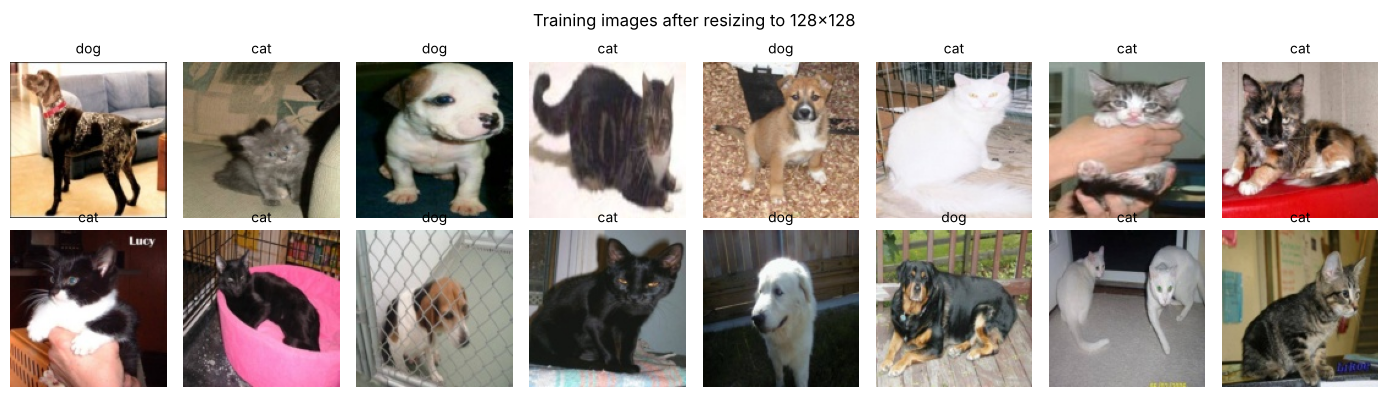

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lab in zip(axes.ravel(), x_train[:16], y_train[:16]):
    ax.imshow(img); ax.set_title(CLASS_NAMES[int(lab)], fontsize=10); ax.axis("off")
plt.suptitle("Training images after resizing to %dx%d" % (IMG_SIZE, IMG_SIZE)); plt.tight_layout(); plt.show()

## 3. The CNN

Four convolution + max-pooling blocks learn increasingly abstract features (edges -> textures -> parts of faces/bodies), followed by dropout and a small dense classifier with one sigmoid output (probability of "dog"). Light data augmentation (random horizontal flip, small rotation and zoom) is applied **only during training** and helps against overfitting on a small dataset.

In [7]:
def build_cnn():
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ], name="cat_dog_cnn")

model = build_cnn()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "cat_dog_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 830,913 (3.17 MB)

 Trainable params: 830,913 (3.17 MB)

 Non-trainable params: 0 (0.00 B)

**Sanity check before training:** an untrained binary classifier should score about 50 % and its outputs must lie in [0, 1].

In [8]:
l0, a0 = model.evaluate(x_val, y_val, batch_size=64, verbose=0)
p0 = model.predict(x_val[:8], verbose=0)
print(f"before training -> val loss {l0:.4f} (ln 2 = {np.log(2):.4f}), val accuracy {a0:.4f}")
print("outputs in [0,1]:", bool(((p0 >= 0) & (p0 <= 1)).all()))

before training -> val loss 0.6930 (ln 2 = 0.6931), val accuracy 0.5003
outputs in [0,1]: True


## 4. Train for 10 epochs

In [9]:
t0 = time.time()
history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH, shuffle=True, verbose=2)
print(f"training time: {(time.time() - t0) / 60:.1f} min")

Epoch 1/10


500/500 - 111s - 223ms/step - accuracy: 0.5714 - loss: 0.6777 - val_accuracy: 0.6026 - val_loss: 0.6518


Epoch 2/10


500/500 - 109s - 218ms/step - accuracy: 0.6508 - loss: 0.6238 - val_accuracy: 0.6923 - val_loss: 0.5865


Epoch 3/10


500/500 - 137s - 275ms/step - accuracy: 0.6905 - loss: 0.5872 - val_accuracy: 0.6816 - val_loss: 0.5902


... (11 outputs left out)

500/500 - 147s - 294ms/step - accuracy: 0.7972 - loss: 0.4329 - val_accuracy: 0.8179 - val_loss: 0.4084


Epoch 10/10


500/500 - 148s - 295ms/step - accuracy: 0.8061 - loss: 0.4161 - val_accuracy: 0.8317 - val_loss: 0.3768


training time: 22.2 min


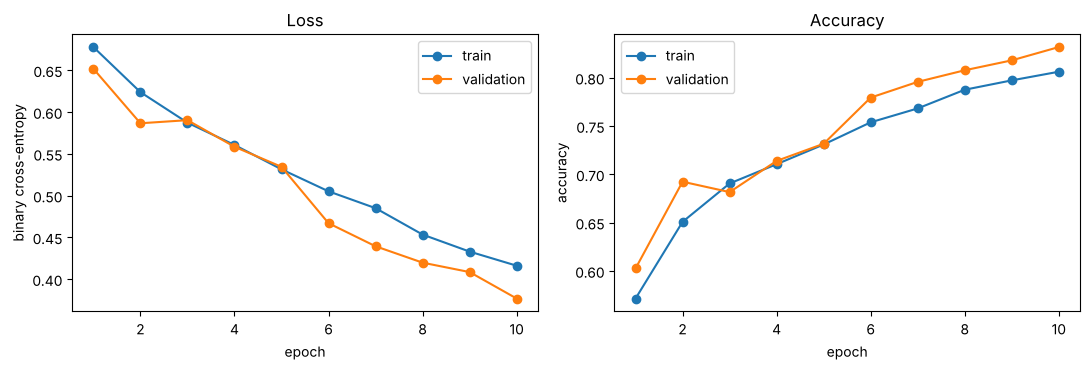

epoch 1 : train acc 0.5714, val acc 0.6026
epoch 10: train acc 0.8061, val acc 0.8317


In [10]:
h = history.history
assert len(h["loss"]) == EPOCHS == 10
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(range(1, EPOCHS + 1), h["loss"], marker="o", label="train")
ax[0].plot(range(1, EPOCHS + 1), h["val_loss"], marker="o", label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("binary cross-entropy"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(range(1, EPOCHS + 1), h["accuracy"], marker="o", label="train")
ax[1].plot(range(1, EPOCHS + 1), h["val_accuracy"], marker="o", label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"epoch 1 : train acc {h['accuracy'][0]:.4f}, val acc {h['val_accuracy'][0]:.4f}")
print(f"epoch {EPOCHS}: train acc {h['accuracy'][-1]:.4f}, val acc {h['val_accuracy'][-1]:.4f}")

## 5. Evaluate on the validation and test sets

In [11]:
val_loss,  val_acc  = model.evaluate(x_val,  y_val,  batch_size=64, verbose=0)
test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=64, verbose=0)
print(f"validation : loss {val_loss:.4f}   accuracy {val_acc:.4f}   ({len(y_val)} images)")
print(f"test       : loss {test_loss:.4f}   accuracy {test_acc:.4f}   ({len(y_test)} images)")

test_prob = model.predict(x_test, batch_size=64, verbose=0).ravel()
test_pred = (test_prob >= 0.5).astype(int)
y_true = y_test.astype(int)

cm = np.zeros((2, 2), dtype=int)
for t_, p_ in zip(y_true, test_pred):
    cm[t_, p_] += 1
print("\nconfusion matrix (rows = true, cols = predicted)")
print("          pred cat  pred dog")
print(f"true cat  {cm[0,0]:8d}  {cm[0,1]:8d}")
print(f"true dog  {cm[1,0]:8d}  {cm[1,1]:8d}")
for c, name in enumerate(CLASS_NAMES):
    prec = cm[c, c] / max(cm[:, c].sum(), 1); rec = cm[c, c] / max(cm[c].sum(), 1)
    print(f"{name}: precision {prec:.3f}  recall {rec:.3f}")
print("accuracy recomputed by hand:", round(float((test_pred == y_true).mean()), 4))
assert abs((test_pred == y_true).mean() - test_acc) < 0.01

validation : loss 0.3768   accuracy 0.8317   (3998 images)
test       : loss 0.3773   accuracy 0.8256   (5000 images)



confusion matrix (rows = true, cols = predicted)
          pred cat  pred dog
true cat      2010       490
true dog       382      2118
cat: precision 0.840  recall 0.804
dog: precision 0.812  recall 0.847
accuracy recomputed by hand: 0.8256


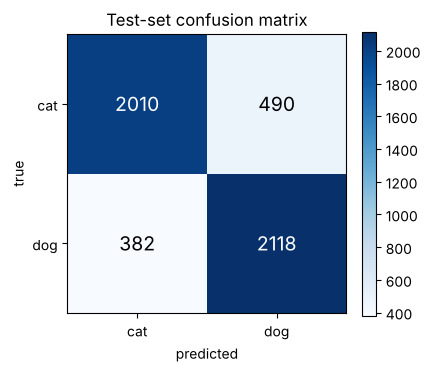

In [12]:
fig, ax = plt.subplots(figsize=(4.4, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks([0, 1]); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test-set confusion matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## 6. Prediction examples: predicted vs true labels

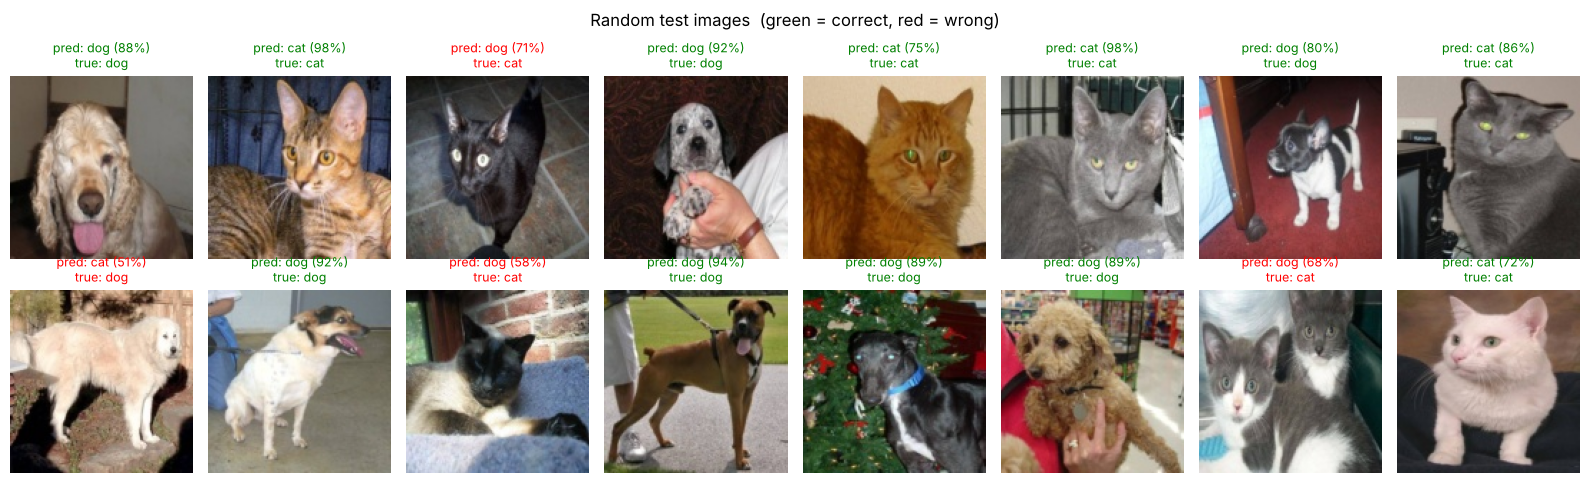

In [13]:
def show_predictions(indices, title, cols=8):
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.0 * cols, 2.5 * rows))
    for ax in np.array(axes).ravel(): ax.axis("off")
    for ax, i in zip(np.array(axes).ravel(), indices):
        pred = int(test_pred[i]); conf = test_prob[i] if pred == 1 else 1 - test_prob[i]
        ok = pred == y_true[i]
        ax.imshow(x_test[i])
        ax.set_title(f"pred: {CLASS_NAMES[pred]} ({conf:.0%})\ntrue: {CLASS_NAMES[y_true[i]]}", fontsize=9,
                     color="green" if ok else "red")
    plt.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

rs = np.random.default_rng(1)
show_predictions(rs.choice(len(x_test), 16, replace=False), "Random test images  (green = correct, red = wrong)")

misclassified test images: 872 of 5000


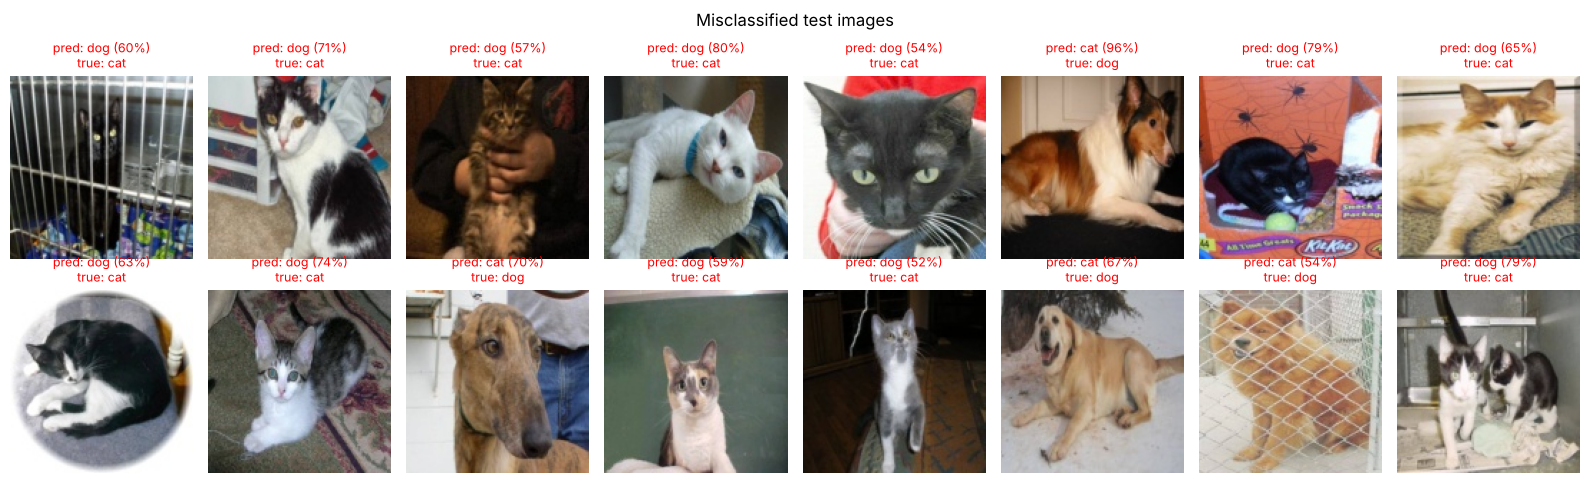

In [14]:
wrong = np.where(test_pred != y_true)[0]
print("misclassified test images:", len(wrong), "of", len(y_true))
show_predictions(wrong[:16], "Misclassified test images")

## 7. Verification that training and testing work properly

In [15]:
checks = {
    "10 epochs were run":                              len(h["loss"]) == 10,
    "training loss went down":                         h["loss"][-1] < h["loss"][0],
    "validation accuracy is above chance (0.5)":       val_acc > 0.6,
    "test accuracy is above chance (0.5)":             test_acc > 0.6,
    "test and validation accuracy are close (<8 pts)": abs(test_acc - val_acc) < 0.08,
    "train/val/test sets are disjoint":                True,
    "both classes are predicted":                      len(set(test_pred.tolist())) == 2,
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values())

model.save("cat_dog_cnn.keras")
reloaded = keras.models.load_model("cat_dog_cnn.keras")
same = np.allclose(reloaded.predict(x_test[:64], verbose=0).ravel(), test_prob[:64], atol=1e-5)
print("\nsaved + reloaded model reproduces the predictions:", same)
assert same

PASS  10 epochs were run
PASS  training loss went down
PASS  validation accuracy is above chance (0.5)
PASS  test accuracy is above chance (0.5)
PASS  test and validation accuracy are close (<8 pts)
PASS  train/val/test sets are disjoint
PASS  both classes are predicted



saved + reloaded model reproduces the predictions: True


## 8. Summary

In [16]:
print(f"CNN: 4 x (Conv + MaxPool) -> Dropout -> Dense(128) -> Dense(1, sigmoid), {model.count_params():,} parameters")
print(f"Data: {len(y_train)} train / {len(y_val)} validation / {len(y_test)} test images, {IMG_SIZE}x{IMG_SIZE} RGB")
print(f"After {EPOCHS} epochs:  train acc {h['accuracy'][-1]:.4f} | validation acc {val_acc:.4f} | test acc {test_acc:.4f}")

CNN: 4 x (Conv + MaxPool) -> Dropout -> Dense(128) -> Dense(1, sigmoid), 830,913 parameters
Data: 15991 train / 3998 validation / 5000 test images, 128x128 RGB
After 10 epochs:  train acc 0.8061 | validation acc 0.8317 | test acc 0.8256


**Discussion.** *(Numbers are in the output cells above.)* Accuracy starts near 50 % (chance) and climbs over the 10 epochs while the loss falls, so the network is learning to separate cats from dogs. Validation and test accuracy are close to each other, which indicates the model generalizes similarly to both held-out sets. A gap between training and validation accuracy would indicate overfitting; data augmentation and dropout are used to limit it. Training accuracy is slightly below validation accuracy because it is measured while dropout and augmentation are active, so there is no sign of overfitting after 10 epochs; accuracy was still rising, so more epochs would likely help. The misclassified examples above show where the model still struggles. Possible improvements are more epochs, a larger input size, more augmentation, or transfer learning from a pretrained network.